1. Загрузка библиотек и настроек

In [61]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from main_project.config import (
    DATA_PROCESSED,
    TARGET,
    RANDOM_STATE,
    TEST_SIZE,
)

DATA_FULL = DATA_PROCESSED / "telco_encoded_full.csv"

sns.set_theme(style="whitegrid")

print("Рабочая папка:", Path.cwd())
print("Путь к данным:", DATA_FULL)
print("Файл существует:", DATA_FULL.exists())
print("Целевая переменная:", TARGET)
print("Случайное состояние:", RANDOM_STATE)
print("Размер тестовой выборки:", TEST_SIZE)

Рабочая папка: c:\Users\Rosey\ProjectChotoTam\notebooks
Путь к данным: C:\Users\Rosey\ProjectChotoTam\data\processed\telco_encoded_full.csv
Файл существует: True
Целевая переменная: Churn Value
Случайное состояние: 42
Размер тестовой выборки: 0.2


2. Загрузка подготовленного датасета

In [62]:
df = pd.read_csv(DATA_FULL)

print("Данные успешно загружены.")
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

display(df.head())

Данные успешно загружены.
Количество строк: 7043
Количество столбцов: 25


,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Monthly Charges,Total Charges,Churn Value,Internet Service_Fiber optic,Internet Service_No,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,33.964,-118.273,1,0,0,0,2,1,0,1,1,0,0,0,0,0,1,53.850,108.150,1,0,0,0,0,1
1,34.059,-118.307,0,0,0,1,2,1,0,0,0,0,0,0,0,0,1,70.700,151.650,1,1,0,0,1,0
2,34.048,-118.294,0,0,0,1,8,1,1,0,0,1,0,1,1,0,1,99.650,820.500,1,1,0,0,1,0
3,34.062,-118.316,0,0,1,1,28,1,1,0,0,1,1,1,1,0,1,104.800,3046.050,1,1,0,0,1,0
4,34.039,-118.266,1,0,0,1,49,1,1,0,1,1,0,1,1,0,1,103.700,5036.300,1,1,0,0,0,0


3. Проверка структуры и качества данных

In [63]:
print("=" * 60)
print("ИНФОРМАЦИЯ О ДАТАСЕТЕ")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("ПРОПУСКИ")
print("=" * 60)

missing = df.isna().sum()
missing = missing[missing > 0]

if missing.empty:
    print("Пропусков не обнаружено.")
else:
    display(missing.sort_values(ascending=False))

print("\n" + "=" * 60)
print("ПОЛНЫЕ ДУБЛИКАТЫ")
print("=" * 60)

duplicates_count = df.duplicated().sum()
print("Количество полных дубликатов:", duplicates_count)

print("\n" + "=" * 60)
print("ТИПЫ ДАННЫХ")
print("=" * 60)

display(
    df.dtypes.rename("Тип данных").to_frame()
)

ИНФОРМАЦИЯ О ДАТАСЕТЕ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 25 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Latitude                                7043 non-null   float64
 1   Longitude                               7043 non-null   float64
 2   Gender                                  7043 non-null   int64  
 3   Senior Citizen                          7043 non-null   int64  
 4   Partner                                 7043 non-null   int64  
 5   Dependents                              7043 non-null   int64  
 6   Tenure Months                           7043 non-null   int64  
 7   Phone Service                           7043 non-null   int64  
 8   Multiple Lines                          7043 non-null   int64  
 9   Online Security                         7043 non-null   int64  
 10  Online Backup                         

,Тип данных
Latitude,float64
Longitude,float64
Gender,int64
Senior Citizen,int64
Partner,int64
Dependents,int64
Tenure Months,int64
Phone Service,int64
Multiple Lines,int64
Online Security,int64


А. Единый отчёт о качестве данных

In [64]:
quality_report = pd.DataFrame({
    "Показатель": [
        "Количество строк",
        "Количество столбцов",
        "Количество пропусков",
        "Количество полных дубликатов",
        "Количество числовых столбцов",
        "Количество нечисловых столбцов",
        "Количество признаков без целевой переменной",
        "Количество классов целевой переменной",
    ],
    "Значение": [
        df.shape[0],
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        len(df.select_dtypes(include=np.number).columns),
        len(df.select_dtypes(exclude=np.number).columns),
        df.drop(columns=[TARGET]).shape[1],
        df[TARGET].nunique(),
    ],
})

display(quality_report)

,Показатель,Значение
0,Количество строк,7043
1,Количество столбцов,25
2,Количество пропусков,0
3,Количество полных дубликатов,0
4,Количество числовых столбцов,25
5,Количество нечисловых столбцов,0
6,Количество признаков без целевой переменной,24
7,Количество классов целевой переменной,2


3.1. Сводная статистика

In [65]:
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Latitude,7043.000,36.282,2.456,32.556,34.031,36.392,38.225,41.962
Longitude,7043.000,-119.799,2.158,-124.301,-121.815,-119.731,-118.043,-114.193
Gender,7043.000,0.505,0.500,0.000,0.000,1.000,1.000,1.000
Senior Citizen,7043.000,0.162,0.369,0.000,0.000,0.000,0.000,1.000
Partner,7043.000,0.483,0.500,0.000,0.000,0.000,1.000,1.000
Dependents,7043.000,0.231,0.422,0.000,0.000,0.000,0.000,1.000
Tenure Months,7043.000,32.371,24.559,0.000,9.000,29.000,55.000,72.000
Phone Service,7043.000,0.903,0.296,0.000,1.000,1.000,1.000,1.000
Multiple Lines,7043.000,0.422,0.494,0.000,0.000,0.000,1.000,1.000
Online Security,7043.000,0.287,0.452,0.000,0.000,0.000,1.000,1.000


4. Проверка целевой переменной

In [66]:
if TARGET not in df.columns:
    raise KeyError(
        f"Целевая переменная {TARGET!r} отсутствует в датасете."
    )

target_counts = df[TARGET].value_counts().sort_index()
target_percentages = (
    df[TARGET]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

target_summary = pd.DataFrame({
    "Количество": target_counts,
    "Доля, %": target_percentages.round(2),
})

display(target_summary)

,Количество,"Доля, %"
Churn Value,,
0,5174,73.460
1,1869,26.540


Теперь построим график:

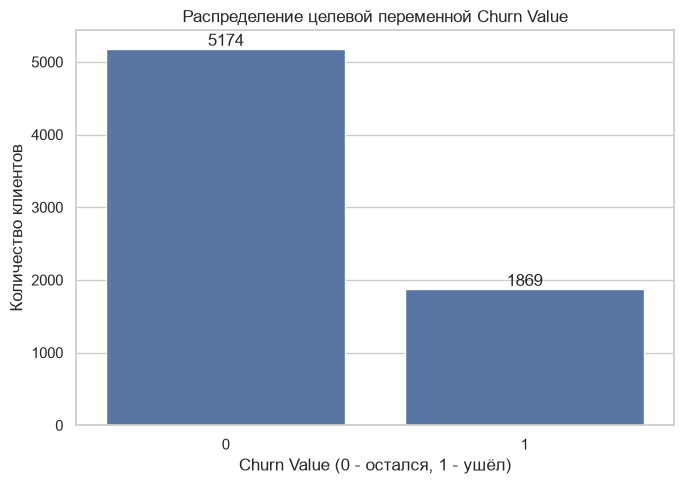

In [67]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x=TARGET,
    order=sorted(df[TARGET].dropna().unique()),
)

ax.set_title("Распределение целевой переменной Churn Value")
ax.set_xlabel("Churn Value (0 - остался, 1 - ушёл)")
ax.set_ylabel("Количество клиентов")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

5. Проверка признаков и возможной утечки данных

In [68]:
from main_project.config import LEAKAGE

leakage_columns = [
    column for column in LEAKAGE
    if column in df.columns
]

if leakage_columns:
    print("Обнаружены потенциальные признаки утечки:")
    print(leakage_columns)
else:
    print("Столбцы из списка потенциальной утечки не обнаружены.")

Столбцы из списка потенциальной утечки не обнаружены.


5.1. Проверка числовых признаков

In [69]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
non_numeric_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Количество числовых столбцов:", len(numeric_columns))
print("Количество нечисловых столбцов:", len(non_numeric_columns))

if non_numeric_columns:
    print("\nНечисловые столбцы:")
    print(non_numeric_columns)
else:
    print("Все столбцы имеют числовой тип.")

Количество числовых столбцов: 25
Количество нечисловых столбцов: 0
Все столбцы имеют числовой тип.


5.2. Анализ числовых признаков

In [70]:
numeric_features = df.drop(columns=[TARGET]).select_dtypes(
    include=np.number
)

display(numeric_features.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Latitude,7043.000,36.282,2.456,32.556,34.031,36.392,38.225,41.962
Longitude,7043.000,-119.799,2.158,-124.301,-121.815,-119.731,-118.043,-114.193
Gender,7043.000,0.505,0.500,0.000,0.000,1.000,1.000,1.000
Senior Citizen,7043.000,0.162,0.369,0.000,0.000,0.000,0.000,1.000
Partner,7043.000,0.483,0.500,0.000,0.000,0.000,1.000,1.000
Dependents,7043.000,0.231,0.422,0.000,0.000,0.000,0.000,1.000
Tenure Months,7043.000,32.371,24.559,0.000,9.000,29.000,55.000,72.000
Phone Service,7043.000,0.903,0.296,0.000,1.000,1.000,1.000,1.000
Multiple Lines,7043.000,0.422,0.494,0.000,0.000,0.000,1.000,1.000
Online Security,7043.000,0.287,0.452,0.000,0.000,0.000,1.000,1.000


Построим гистограммы для числовых признаков:

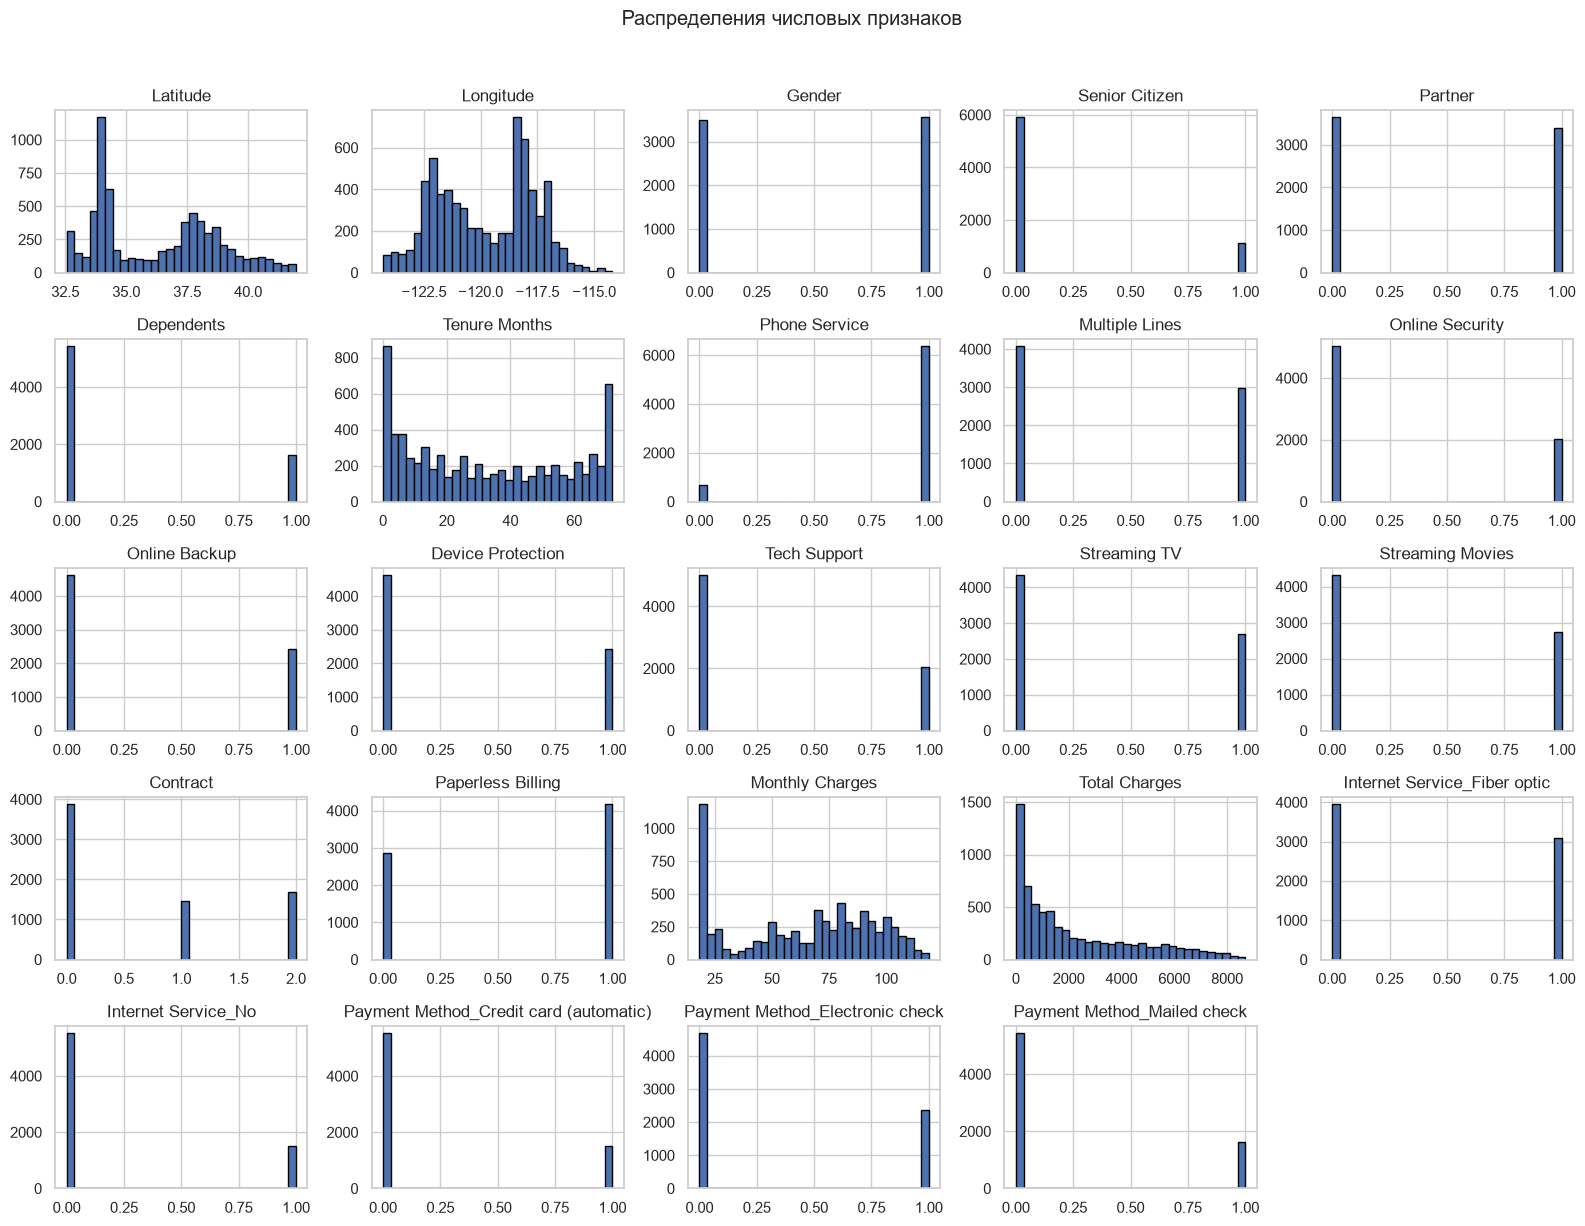

In [71]:
numeric_features.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black",
)

plt.suptitle(
    "Распределения числовых признаков",
    y=1.02,
)

plt.tight_layout()
plt.show()

Б. Проверка диапазонов и выбросов

In [72]:
numeric_features = df.drop(columns=[TARGET]).select_dtypes(
    include=np.number
)

Q1 = numeric_features.quantile(0.25)
Q3 = numeric_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    (numeric_features.lt(lower_bound) |
     numeric_features.gt(upper_bound))
    .sum()
    .sort_values(ascending=False)
)

outlier_report = outlier_counts.to_frame(
    "Количество потенциальных выбросов"
)

outlier_report["Доля, %"] = (
    outlier_report["Количество потенциальных выбросов"]
    / len(df) * 100
).round(2)

display(outlier_report)

,Количество потенциальных выбросов,"Доля, %"
Dependents,1627,23.100
Payment Method_Mailed check,1612,22.890
Internet Service_No,1526,21.670
Payment Method_Credit card (automatic),1522,21.610
Senior Citizen,1142,16.210
Phone Service,682,9.680
Gender,0,0.000
Latitude,0,0.000
Tenure Months,0,0.000
Partner,0,0.000


5.3. Проверка географических координат

In [73]:
if {"Latitude", "Longitude"}.issubset(df.columns):
    print("Диапазон широты:")
    print(df["Latitude"].describe())

    print("\nДиапазон долготы:")
    print(df["Longitude"].describe())

    suspicious_coordinates = df.loc[
        df["Longitude"] > 0,
        ["Latitude", "Longitude"],
    ]

    print(
        "\nКоличество записей с положительной долготой:",
        len(suspicious_coordinates),
    )

    display(suspicious_coordinates.head(20))
else:
    print("Координаты отсутствуют в подготовленном датасете.")

Диапазон широты:
count   7043.000
mean      36.282
std        2.456
min       32.556
25%       34.031
50%       36.392
75%       38.225
max       41.962
Name: Latitude, dtype: float64

Диапазон долготы:
count   7043.000
mean    -119.799
std        2.158
min     -124.301
25%     -121.815
50%     -119.731
75%     -118.043
max     -114.193
Name: Longitude, dtype: float64

Количество записей с положительной долготой: 0


,Latitude,Longitude


В. Проверка долготы

In [74]:
print("Минимальная долгота:", df["Longitude"].min())
print("Максимальная долгота:", df["Longitude"].max())
print("Количество положительных долгот:", (df["Longitude"] > 0).sum())

Минимальная долгота: -124.301372
Максимальная долгота: -114.192901
Количество положительных долгот: 0


5.4. Корреляция числовых признаков с целевой переменной

In [75]:
correlations = (
    df.corr(numeric_only=True)[TARGET]
    .drop(labels=[TARGET])
    .dropna()
    .sort_values()
)

display(
    correlations.to_frame("Корреляция с Churn Value")
    .round(3)
)

,Корреляция с Churn Value
Contract,-0.397
Tenure Months,-0.352
Dependents,-0.249
Internet Service_No,-0.228
Total Charges,-0.198
Online Security,-0.171
Tech Support,-0.165
Partner,-0.150
Payment Method_Credit card (automatic),-0.134
Payment Method_Mailed check,-0.092


Покажем признаки с наибольшими по модулю значениями корреляции:

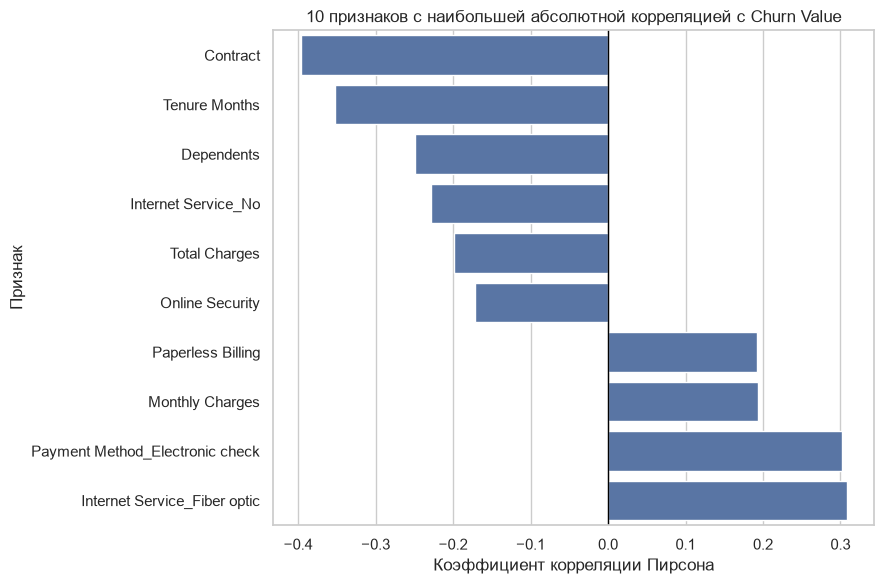

In [76]:
top_correlations = correlations.loc[
    correlations.abs()
    .sort_values(ascending=False)
    .head(10)
    .index
].sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_correlations.values,
    y=top_correlations.index,
)

plt.axvline(0, color="black", linewidth=1)
plt.title("10 признаков с наибольшей абсолютной корреляцией с Churn Value")
plt.xlabel("Коэффициент корреляции Пирсона")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

Г. Проверка списка признаков и кодирования

In [77]:
print("Целевая переменная:", TARGET)
print("Количество признаков:", len(X.columns))
print("\nСписок признаков:")

for i, column in enumerate(X.columns, start=1):
    print(f"{i}. {column}")

Целевая переменная: Churn Value
Количество признаков: 24

Список признаков:
1. Latitude
2. Longitude
3. Gender
4. Senior Citizen
5. Partner
6. Dependents
7. Tenure Months
8. Phone Service
9. Multiple Lines
10. Online Security
11. Online Backup
12. Device Protection
13. Tech Support
14. Streaming TV
15. Streaming Movies
16. Contract
17. Paperless Billing
18. Monthly Charges
19. Total Charges
20. Internet Service_Fiber optic
21. Internet Service_No
22. Payment Method_Credit card (automatic)
23. Payment Method_Electronic check
24. Payment Method_Mailed check


6. Формирование признаков и целевой переменной

In [78]:
# Проверяем значения целевой переменной
target_values = set(df[TARGET].dropna().unique())

if not target_values.issubset({0, 1}):
    raise ValueError(
        f"Ожидалась бинарная целевая переменная 0/1, "
        f"получены значения: {target_values}"
    )

# Формируем матрицу признаков и целевую переменную
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

print("Матрица признаков X:", X.shape)
print("Целевая переменная y:", y.shape)

print("\nРаспределение целевой переменной:")
display(y.value_counts().sort_index().to_frame("Количество"))

print("\nЦелевая переменная присутствует в X:", TARGET in X.columns)
print("Пропуски в X:", X.isna().sum().sum())
print("Пропуски в y:", y.isna().sum())

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
print("Нечисловые признаки:", non_numeric)

Матрица признаков X: (7043, 24)
Целевая переменная y: (7043,)

Распределение целевой переменной:


,Количество
Churn Value,
0,5174
1,1869



Целевая переменная присутствует в X: False
Пропуски в X: 0
Пропуски в y: 0
Нечисловые признаки: []


6.1. Контрольные проверки

In [79]:
assert len(X) == len(y), "Количество строк в X и y не совпадает."
assert TARGET not in X.columns, "Целевая переменная попала в X."
assert y.notna().all(), "В целевой переменной обнаружены пропуски."
assert X.notna().all().all(), "В матрице признаков обнаружены пропуски."
assert not non_numeric, (
    f"Найдены нечисловые признаки: {non_numeric}"
)

print("Все контрольные проверки пройдены.")
print("Данные готовы к дальнейшим экспериментам.")

Все контрольные проверки пройдены.
Данные готовы к дальнейшим экспериментам.


7. Итоговый вывод для ноутбука

В ходе анализа был загружен подготовленный датасет клиентов телекоммуникационной компании. Проведена проверка структуры данных, типов признаков, пропусков и полных дубликатов.

Отдельное внимание уделено целевой переменной `Churn Value`, которая отражает факт ухода клиента. Анализ её распределения позволяет оценить соотношение классов и учитывать возможный дисбаланс при последующем сравнении моделей.

Также проверены известные потенциально проблемные признаки, числовые распределения, корреляции с целевой переменной и географические координаты. Необычные значения требуют дополнительной проверки, а не автоматического удаления.

В завершение сформированы матрица признаков `X` и целевая переменная `y`. Они подготовлены для последующих экспериментов по сравнению методов разделения выборки и оценки качества модели.